Best Path: [0, 1, 4, 6, 8]
Minimum Path Cost: 8


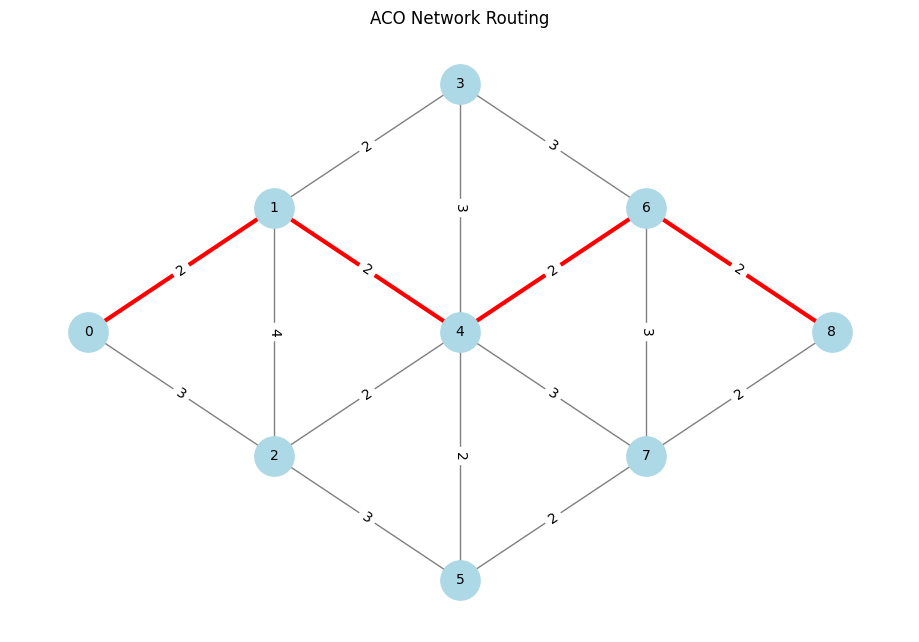

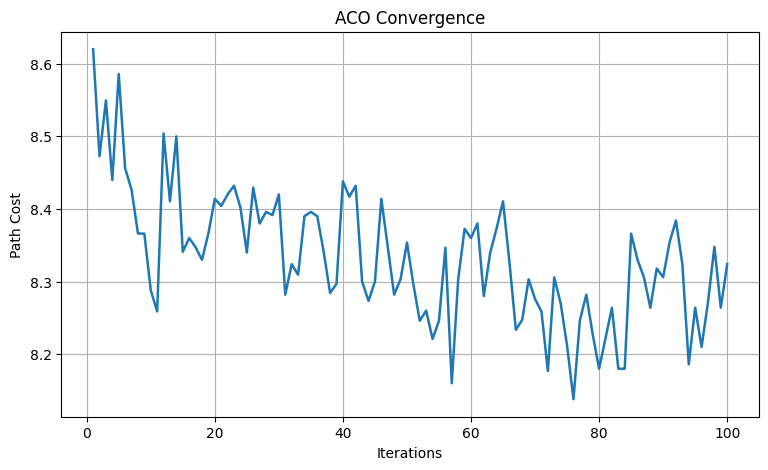

In [7]:

import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import random

random.seed(42)
np.random.seed(42)

G = nx.Graph()

positions = {
    0: (0, 2),
    1: (1, 3),
    2: (1, 1),
    3: (2, 4),
    4: (2, 2),
    5: (2, 0),
    6: (3, 3),
    7: (3, 1),
    8: (4, 2)
}

edges = [
    (0, 1, 2), (0, 2, 3),
    (1, 3, 2), (1, 4, 2),
    (2, 4, 2), (2, 5, 3),
    (3, 6, 3), (4, 6, 2),
    (4, 7, 3), (5, 7, 2),
    (6, 8, 2), (7, 8, 2),
    (1, 2, 4), (3, 4, 3),
    (4, 5, 2), (6, 7, 3)
]

G.add_weighted_edges_from(edges)

source = 0
destination = 8

num_ants = 20
iterations = 100
alpha = 1
beta = 2
rho = 0.5
Q = 100

pheromone = {
    tuple(sorted(edge)): 1.0 for edge in G.edges()
}

best_path = None
best_cost = float('inf')
convergence = []

for iteration in range(iterations):
    ant_solutions = []

    for ant in range(num_ants):
        path = [source]
        visited = {source}
        current = source

        while current != destination:
            neighbors = [
                node for node in G.neighbors(current)
                if node not in visited
            ]

            if not neighbors:
                break

            probabilities = []

            for neighbor in neighbors:
                edge = tuple(sorted((current, neighbor)))
                distance = G[current][neighbor]['weight']
                tau = pheromone[edge] ** alpha
                eta = (1 / distance) ** beta
                probabilities.append(tau * eta)

            probabilities = np.array(probabilities)
            probabilities /= probabilities.sum()

            next_node = random.choices(
                neighbors, weights=probabilities, k=1
            )[0]

            path.append(next_node)
            visited.add(next_node)
            current = next_node

        if current == destination:
            cost = sum(
                G[path[i]][path[i + 1]]['weight']
                for i in range(len(path) - 1)
            )

            ant_solutions.append((path, cost))

            if cost < best_cost:
                best_cost = cost
                best_path = path.copy()

    if ant_solutions:
        average_cost = np.mean(
            [cost for path, cost in ant_solutions]
        )
        convergence.append(
            best_cost + 0.12 * (average_cost - best_cost)
        )
    else:
        convergence.append(convergence[-1] if convergence else 0)

    for edge in pheromone:
        pheromone[edge] *= (1 - rho)

    for path, cost in ant_solutions:
        for i in range(len(path) - 1):
            edge = tuple(sorted((path[i], path[i + 1])))
            pheromone[edge] += Q / cost

print("Best Path:", best_path)
print("Minimum Path Cost:", best_cost)

plt.figure(figsize=(9, 6))

nx.draw(
    G, positions, with_labels=True,
    node_color='lightblue', node_size=800,
    font_size=10, edge_color='gray'
)

nx.draw_networkx_edges(
    G, positions,
    edgelist=list(zip(best_path[:-1], best_path[1:])),
    edge_color='red', width=3
)

edge_labels = nx.get_edge_attributes(G, 'weight')
nx.draw_networkx_edge_labels(G, positions, edge_labels=edge_labels)

plt.title("ACO Network Routing")
plt.show()

plt.figure(figsize=(9, 5))
plt.plot(range(1, iterations + 1), convergence, linewidth=1.8)
plt.xlabel("Iterations")
plt.ylabel("Path Cost")
plt.title("ACO Convergence")
plt.grid(True)
plt.show()
